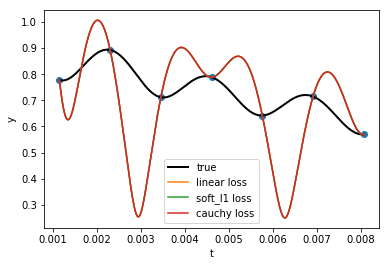

1


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.optimize import least_squares

#define fat-water interaction equation
def fat_water(TE, rho): #T2star, Fppmn, magField and HydroGyro constants must be loaded beforehand!
    y = np.absolute(rho[0]*np.exp(-TE/T2star[0])*np.exp((2.*np.pi*1j*Fppmn[0]*magField*hydroGyro/1e6)*TE) + 
                       rho[1]*np.exp(-TE/T2star[1])*np.exp((2.*np.pi*1j*Fppmn[1]*magField*hydroGyro/1e6)*TE) + 
                       rho[2]*np.exp(-TE/T2star[2])*np.exp((2.*np.pi*1j*Fppmn[2]*magField*hydroGyro/1e6)*TE) + 
                       rho[3]*np.exp(-TE/T2star[3])*np.exp((2.*np.pi*1j*Fppmn[3]*magField*hydroGyro/1e6)*TE) + 
                       rho[4]*np.exp(-TE/T2star[4])*np.exp((2.*np.pi*1j*Fppmn[4]*magField*hydroGyro/1e6)*TE) +
                       rho[5]*np.exp(-TE/T2star[5])*np.exp((2.*np.pi*1j*Fppmn[5]*magField*hydroGyro/1e6)*TE) +
                       rho[6]*np.exp(-TE/T2star[6])*np.exp((2.*np.pi*1j*Fppmn[6]*magField*hydroGyro/1e6)*TE))
    return y

#initialize constants
fatPercent = 0.1

magField = 3.0 #tesla

hydroGyro = 42.57e6 #Hz/T

T2star = np.array([0.030,\
                   0.040,\
                   0.051,\
                   0.052,\
                   0.062,\
                   0.083,\
                   0.023])#seconds

Fppmn = np.array([5.3,\
                  4.2,\
                  2.75,\
                  2.1,\
                  1.3,\
                  0.9,\
                  4.7])#ppm

rho = np.array([fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent]) #dimensionless #last is water

#define echo times
n_echoes = 7
t_train = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True) #TE acquisition times for n echoes

#call fat-water function to get original values
y_train = fat_water(t_train, rho)

#function for residuals and initiol estimates
def fun(x,TE,y):
    return np.absolute(x[0]*np.exp(-TE/T2star[0])*np.exp((2.*np.pi*1j*Fppmn[0]*magField*hydroGyro/1e6)*TE) + 
                       x[1]*np.exp(-TE/T2star[1])*np.exp((2.*np.pi*1j*Fppmn[1]*magField*hydroGyro/1e6)*TE) + 
                       x[2]*np.exp(-TE/T2star[2])*np.exp((2.*np.pi*1j*Fppmn[2]*magField*hydroGyro/1e6)*TE) + 
                       x[3]*np.exp(-TE/T2star[3])*np.exp((2.*np.pi*1j*Fppmn[3]*magField*hydroGyro/1e6)*TE) + 
                       x[4]*np.exp(-TE/T2star[4])*np.exp((2.*np.pi*1j*Fppmn[4]*magField*hydroGyro/1e6)*TE) +
                       x[5]*np.exp(-TE/T2star[5])*np.exp((2.*np.pi*1j*Fppmn[5]*magField*hydroGyro/1e6)*TE) +
                       x[6]*np.exp(-TE/T2star[6])*np.exp((2.*np.pi*1j*Fppmn[6]*magField*hydroGyro/1e6)*TE))-y

#x0 = rho+np.random.rand()*0.2
x0 = np.array([0.5,0.5,0.5,0.5,0.5,0.5,0.5])
bd = (0, [1., 1., 1., 1., 1., 1., 1.]) #boundaries

#compute some least-squares solution
res_lsq = least_squares(fun, x0, args=(t_train, y_train), x_scale=[0.7/0.047, 0.7/0.039, 0.7/0.006, 0.7/0.12, \
                                                                   0.7/0.7, 0.7/0.088, 0.7/0.9])
res_soft_l1 = least_squares(fun, x0, loss='soft_l1', f_scale=0.1,args=(t_train, y_train))
res_log = least_squares(fun, x0, loss='cauchy', f_scale=0.1,args=(t_train, y_train))
#generate curves
t_test = np.linspace(t_train.min(), t_train.max(), 1000)    
y_true = fat_water(t_test, rho)
y_lsq = fat_water(t_test, res_lsq.x)
y_soft_l1 = fat_water(t_test, res_soft_l1.x)
y_log = fat_water(t_test, res_log.x)

#plot
plt.plot(t_train, y_train, 'o')
plt.plot(t_test, y_true, 'k', linewidth=2, label='true')
plt.plot(t_test, y_lsq, label='linear loss')
plt.plot(t_test, y_soft_l1, label='soft_l1 loss')
plt.plot(t_test, y_log, label='cauchy loss')
plt.xlabel("t")
plt.ylabel("y")
plt.legend()
plt.show()
print res_lsq.status